# 115 kWp commercial rooftop, Islamabad: energy yield estimate

How much energy will the rooftop system produce each month and over a year? This notebook works it out from PVGIS solar data for Islamabad, and compares a simple hand calculation with the PVGIS model.

- **System:** 198 Jinko JKM580N-72HL4-V modules (580 W) on one Huawei SUN2000-100KTL-M2 inverter
- **Data:** PVGIS 5.3 (European Commission, Joint Research Centre), ERA5 solar data for 2005 to 2023
- **Assumed:** modules facing south at 20° tilt, 14% system losses (the PVGIS default)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## Step 1: System size

The size of a PV system is the number of modules times the power of one module, in kilowatts peak (kWp).

In [2]:
modules = 198
module_watts = 580

system_kwp = modules * module_watts / 1000
print("System size:", system_kwp, "kWp")

System size: 114.84 kWp


## Step 2: Load the solar data

One row per month:
- **irradiation_kwh_m2:** the sunlight that falls on one square metre of the tilted modules in the month
- **pvgis_kwh_per_kwp:** the energy PVGIS expects from each kWp of modules in the month, after all losses

In [3]:
data = pd.read_csv("pvgis_islamabad_monthly.csv")
data

,month,irradiation_kwh_m2,pvgis_kwh_per_kwp
0,Jan,139.93,111.70
1,Feb,138.95,109.32
2,Mar,179.54,136.21
3,Apr,200.87,147.22
4,May,217.65,154.15
5,Jun,202.50,143.25
6,Jul,171.50,124.70
7,Aug,170.97,126.29
8,Sep,177.20,130.64
9,Oct,180.81,135.51


## Step 3: Energy per month

Two ways to estimate it:
- **Simple estimate:** system size x irradiation x performance ratio (PR). A PR of 0.80 is a common first guess; it covers losses from heat, cables, the inverter and dirt.
- **PVGIS model:** system size x PVGIS energy per kWp. PVGIS works out the heat losses month by month from real temperatures.

The last column is the PR that PVGIS's numbers imply for each month.

In [4]:
pr_assumed = 0.80

data["simple_kwh"] = system_kwp * data["irradiation_kwh_m2"] * pr_assumed
data["pvgis_kwh"] = system_kwp * data["pvgis_kwh_per_kwp"]
data["pvgis_pr"] = data["pvgis_kwh_per_kwp"] / data["irradiation_kwh_m2"]

data.round({"simple_kwh": 0, "pvgis_kwh": 0, "pvgis_pr": 2})

,month,irradiation_kwh_m2,pvgis_kwh_per_kwp,simple_kwh,pvgis_kwh,pvgis_pr
0,Jan,139.93,111.70,12856.0,12828.0,0.80
1,Feb,138.95,109.32,12766.0,12554.0,0.79
2,Mar,179.54,136.21,16495.0,15642.0,0.76
3,Apr,200.87,147.22,18454.0,16907.0,0.73
4,May,217.65,154.15,19996.0,17703.0,0.71
5,Jun,202.50,143.25,18604.0,16451.0,0.71
6,Jul,171.50,124.70,15756.0,14321.0,0.73
7,Aug,170.97,126.29,15707.0,14503.0,0.74
8,Sep,177.20,130.64,16280.0,15003.0,0.74
9,Oct,180.81,135.51,16611.0,15562.0,0.75


## Step 4: Results for the year

In [5]:
year_kwh = data["pvgis_kwh"].sum()
simple_year_kwh = data["simple_kwh"].sum()
specific_yield = year_kwh / system_kwp
year_pr = year_kwh / (system_kwp * data["irradiation_kwh_m2"].sum())

best = data.loc[data["pvgis_kwh"].idxmax()]
worst = data.loc[data["pvgis_kwh"].idxmin()]

print(f"Energy per year (PVGIS):   {year_kwh:,.0f} kWh")
print(f"Simple estimate (PR 0.80): {simple_year_kwh:,.0f} kWh")
print(f"Specific yield:            {specific_yield:,.0f} kWh per kWp")
print(f"Performance ratio (year):  {year_pr:.2f}")
print(f"Best month:  {best['month']}, {best['pvgis_kwh']:,.0f} kWh")
print(f"Worst month: {worst['month']}, {worst['pvgis_kwh']:,.0f} kWh")

Energy per year (PVGIS):   178,296 kWh
Simple estimate (PR 0.80): 190,928 kWh
Specific yield:            1,553 kWh per kWp
Performance ratio (year):  0.75
Best month:  May, 17,703 kWh
Worst month: Feb, 12,554 kWh


## Step 5: Chart

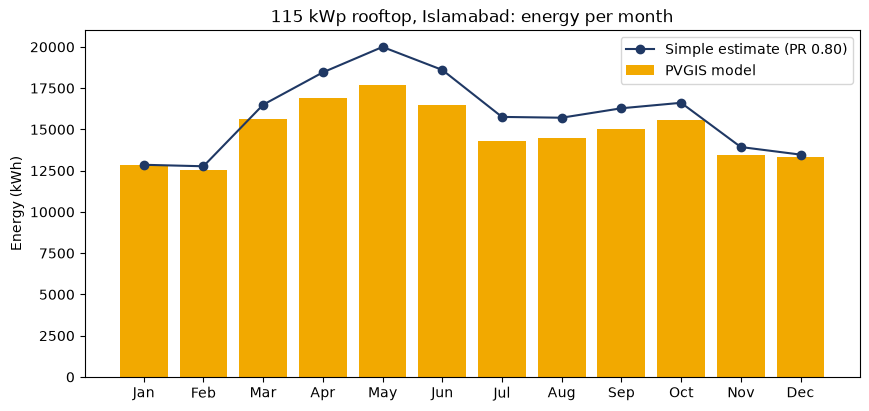

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(data["month"], data["pvgis_kwh"], color="#F2A900", label="PVGIS model")
ax.plot(data["month"], data["simple_kwh"], color="#1F3864", marker="o", label="Simple estimate (PR 0.80)")
ax.set_title("115 kWp rooftop, Islamabad: energy per month")
ax.set_ylabel("Energy (kWh)")
ax.legend()

fig.savefig("monthly_energy.png", dpi=150, bbox_inches="tight")
plt.show()

## What the numbers show

- The system should produce about **178,300 kWh a year**, or **1,553 kWh for every kWp**: about 490 kWh a day on average.
- **May** is the best month (17,703 kWh) and **February** the lowest (12,554 kWh).
- The simple estimate comes out **7% high** over the year. The gap is under 2% in winter but about 11% from May to August: the modules run hot, and the PR falls to 0.71 in May and June, against 0.80 in January.
- So in a hot climate like Islamabad's, a flat PR of 0.80 overstates the yield. A monthly model that uses real temperatures, such as PVGIS, is the better basis for a yield estimate.

**Data source:** PVGIS 5.3 PVcalc, downloaded on 22 Sep 2026 for latitude 33.684, longitude 73.048: 1 kWp of crystalline silicon, free-standing, 20° tilt, facing south, 14% system losses.